# Osa 1: Tekstigeneraattori

## Kirjastot

In [2]:
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'  # You can change to 'jax' or 'torch' if preferred

import re
import time
import numpy as np
import pandas as pd
import keras
import sentencepiece as spm
import matplotlib.pyplot as plt

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.15.1
Keras backend: tensorflow


## Aineisto

In [3]:
# Load the Sherlock Holmes text
TEXT_FILE = './sherlock_puhdas.txt'
with open(TEXT_FILE, 'r', encoding='utf-8-sig') as file:
    text = file.read()

print(f"Text length: {len(text)} characters ({len(text.encode('utf-8'))/1024:.0f} KB)")
print(f"First 100 characters: {text[:100]}")

Text length: 561156 characters (561 KB)
First 100 characters: I. A SCANDAL IN BOHEMIA

I.

To Sherlock Holmes she is always the woman. I have seldom heard him men


## Tokenisointi

In [4]:
def train_tokenizer(vocab_size):
    """Train (or load) a SentencePiece BPE tokenizer with the given vocabulary size."""
    os.makedirs("tokenizers", exist_ok=True)
    model_prefix = f"tokenizers/sherlock_sp_{vocab_size}"
    if not os.path.exists(model_prefix + ".model"):
        spm.SentencePieceTrainer.train(
            input=TEXT_FILE,
            model_prefix=model_prefix,
            vocab_size=vocab_size,
            character_coverage=1.0,
            model_type='bpe',
            user_defined_symbols=['<PAD>', '<UNK>'],
            minloglevel=2
        )
    sp = spm.SentencePieceProcessor()
    sp.load(model_prefix + ".model")
    return sp

sp = train_tokenizer(2000)

# Test tokenization
test_text = "Mr. Sherlock Holmes, who was usually very late in the mornings"
print(f"Tokenized example: {sp.encode_as_pieces(test_text)}")
print(f"Vocabulary size: {sp.get_piece_size()}")
print(f"Total tokens in text: {len(sp.encode_as_ids(text))}")

Tokenized example: ['▁Mr', '.', '▁Sherlock', '▁Holmes', ',', '▁who', '▁was', '▁us', 'ually', '▁very', '▁late', '▁in', '▁the', '▁morning', 's']
Vocabulary size: 2000
Total tokens in text: 162927


In [5]:
# Sanaston koon vaikutus: kuinka monta tokenia teksti vaatii ja kuinka pitkiä paloja tulee
rivit = []
for v in [500, 1000, 2000, 4000, 8000]:
    s = train_tokenizer(v)
    n = len(s.encode_as_ids(text))
    rivit.append({"vocab_size": v, "tokeneita": n, "merkkia_per_token": len(text) / n})
pd.DataFrame(rivit)

,vocab_size,tokeneita,merkkia_per_token
0,500,224730,2.497023
1,1000,189023,2.968718
2,2000,162927,3.444217
3,4000,144010,3.896646
4,8000,131901,4.254373


## Datan valmistelu

In [6]:
def make_data(sp, seq_length, stride, val_fraction=0.1):
    """Tokenize the text and make (input, target) windows. Target is the input shifted by one token."""
    ids = np.array(sp.encode_as_ids(text), dtype=np.int32)

    # Validation set = last part of the text. Splitting before making windows means
    # no token appears in both sets (neighbouring windows would otherwise overlap).
    split = int((1 - val_fraction) * len(ids))
    train_ids, val_ids = ids[:split], ids[split:]

    def windows(a, step):
        w = np.lib.stride_tricks.sliding_window_view(a, seq_length + 1)[::step]
        return w[:, :-1], w[:, 1:]

    train_x, train_y = windows(train_ids, stride)
    val_x, val_y = windows(val_ids, seq_length)
    return train_x, train_y, val_x, val_y

train_x, train_y, val_x, val_y = make_data(sp, seq_length=64, stride=8)
print(f"Train sequences: {train_x.shape}, validation sequences: {val_x.shape}")

Train sequences: (18322, 64), validation sequences: (254, 64)


## Mallin määrittely

In [7]:
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding.astype(np.float32)

def build_model(vocab_size, seq_length, embed_dim, num_heads, ff_dim, num_layers, lr=3e-4):
    inputs = keras.Input(shape=(seq_length,))
    embedding_layer = keras.layers.Embedding(vocab_size, embed_dim)(inputs)

    # Add positional encoding
    x = embedding_layer + get_positional_encoding(seq_length, embed_dim)

    # Transformer blocks
    for _ in range(num_layers):
        # Multi-head attention with causal mask
        attention_output = keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=0.1
        )(x, x, use_causal_mask=True)

        # Add & Norm
        x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

        # Feed-forward network
        ffn = keras.Sequential([
            keras.layers.Dense(ff_dim, activation="relu"),
            keras.layers.Dense(embed_dim),
            keras.layers.Dropout(0.1)
        ])
        ffn_output = ffn(x)

        # Add & Norm
        x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

    # Final output layer
    outputs = keras.layers.Dense(vocab_size)(x)

    model = keras.Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )
    return model

build_model(vocab_size=2000, seq_length=64, embed_dim=64, num_heads=2, ff_dim=128, num_layers=2).summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 64, 64)    │    128,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64)    │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64)    │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64, 2000)  │    130,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Koulutusfunktio

In [8]:
MAX_EPOCHS = 8
STRIDE = 8        # train windows start every STRIDE tokens (1 = all windows, slowest)
BATCH_SIZE = 128

TULOKSET = {}     # nimi -> koulutuksen tulokset ja malli

def kouluta(nimi, vocab_size=2000, seq_length=64, embed_dim=64, num_heads=2, ff_dim=128,
            num_layers=2, epochs=MAX_EPOCHS, stride=STRIDE, batch_size=BATCH_SIZE):
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    sp = train_tokenizer(vocab_size)
    train_x, train_y, val_x, val_y = make_data(sp, seq_length, stride)
    model = build_model(vocab_size, seq_length, embed_dim, num_heads, ff_dim, num_layers)

    print(f"=== {nimi}: {model.count_params()/1e6:.2f} M parameters, {len(train_x)} training sequences ===")
    t0 = time.perf_counter()
    history = model.fit(
        train_x, train_y,
        validation_data=(val_x, val_y),
        batch_size=batch_size,
        epochs=epochs,
        verbose=2,
        callbacks=[
            keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True, verbose=1),
            keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        ]
    )
    aika = time.perf_counter() - t0

    val_loss = min(history.history["val_loss"])
    TULOKSET[nimi] = {
        "model": model, "sp": sp, "history": history.history, "seq_length": seq_length,
        "rivi": {
            "nimi": nimi, "vocab_size": vocab_size, "seq_length": seq_length, "embed_dim": embed_dim,
            "num_heads": num_heads, "ff_dim": ff_dim, "num_layers": num_layers,
            "parametrit_M": round(model.count_params() / 1e6, 2),
            "epookit": len(history.history["loss"]),
            "aika_min": round(aika / 60, 1),
            "val_loss": round(val_loss, 3),
            "perplexity": round(float(np.exp(val_loss)), 1),
            "val_acc": round(max(history.history["val_accuracy"]), 3),
        }
    }
    return TULOKSET[nimi]["rivi"]

def taulukko():
    return pd.DataFrame([t["rivi"] for t in TULOKSET.values()]).set_index("nimi")

## Kokeet: mallin koko

In [9]:
KOOT = {
    "minimi": dict(embed_dim=32,  num_heads=2, ff_dim=64,  num_layers=1),
    "pieni":  dict(embed_dim=64,  num_heads=2, ff_dim=128, num_layers=2),
    "keski":  dict(embed_dim=128, num_heads=4, ff_dim=256, num_layers=3),
    "iso":    dict(embed_dim=256, num_heads=8, ff_dim=512, num_layers=4),
}

for nimi, asetukset in KOOT.items():
    kouluta(nimi, **asetukset)

taulukko()


=== minimi: 0.14 M parameters, 18322 training sequences ===
Epoch 1/8
144/144 - 30s - 211ms/step - accuracy: 0.0233 - loss: 7.0493 - val_accuracy: 0.0407 - val_loss: 6.5794 - learning_rate: 3.0000e-04
Epoch 2/8
144/144 - 27s - 186ms/step - accuracy: 0.0448 - loss: 6.4012 - val_accuracy: 0.0461 - val_loss: 6.3371 - learning_rate: 3.0000e-04
Epoch 3/8
144/144 - 26s - 181ms/step - accuracy: 0.0659 - loss: 6.2098 - val_accuracy: 0.0835 - val_loss: 6.0512 - learning_rate: 3.0000e-04
Epoch 4/8
144/144 - 25s - 170ms/step - accuracy: 0.0934 - loss: 5.8279 - val_accuracy: 0.0988 - val_loss: 5.6981 - learning_rate: 3.0000e-04
Epoch 5/8
144/144 - 26s - 178ms/step - accuracy: 0.1085 - loss: 5.5023 - val_accuracy: 0.1148 - val_loss: 5.4211 - learning_rate: 3.0000e-04
Epoch 6/8
144/144 - 25s - 171ms/step - accuracy: 0.1217 - loss: 5.2545 - val_accuracy: 0.1237 - val_loss: 5.2463 - learning_rate: 3.0000e-04
Epoch 7/8
144/144 - 25s - 172ms/step - accuracy: 0.1317 - loss: 5.0902 - val_accuracy: 0.1302

,vocab_size,seq_length,embed_dim,num_heads,ff_dim,num_layers,parametrit_M,epookit,aika_min,val_loss,perplexity,val_acc
nimi,,,,,,,,,,,,
minimi,2000,64,32,2,64,1,0.14,8,3.4,5.052,156.4,0.139
pieni,2000,64,64,2,128,2,0.32,8,4.7,4.742,114.7,0.160
keski,2000,64,128,4,256,3,0.91,8,10.8,4.522,92.0,0.179
iso,2000,64,256,8,512,4,3.13,8,29.6,4.394,80.9,0.195


## Kokeet: hyperparametrit

In [10]:
# Yksi parametri kerrallaan muutettuna "pieni"-mallista
for seq in [32, 128]:
    kouluta(f"pieni_seq{seq}", seq_length=seq, **KOOT["pieni"])

for v in [1000, 4000]:
    kouluta(f"pieni_vocab{v}", vocab_size=v, **KOOT["pieni"])

taulukko()

=== pieni_seq32: 0.32 M parameters, 18326 training sequences ===
Epoch 1/8
144/144 - 23s - 157ms/step - accuracy: 0.0381 - loss: 6.7592 - val_accuracy: 0.0449 - val_loss: 6.3529 - learning_rate: 3.0000e-04
Epoch 2/8
144/144 - 16s - 108ms/step - accuracy: 0.0445 - loss: 6.3107 - val_accuracy: 0.0682 - val_loss: 6.2848 - learning_rate: 3.0000e-04
Epoch 3/8
144/144 - 16s - 108ms/step - accuracy: 0.0932 - loss: 5.9455 - val_accuracy: 0.1063 - val_loss: 5.6525 - learning_rate: 3.0000e-04
Epoch 4/8
144/144 - 16s - 114ms/step - accuracy: 0.1189 - loss: 5.3897 - val_accuracy: 0.1230 - val_loss: 5.2839 - learning_rate: 3.0000e-04
Epoch 5/8
144/144 - 16s - 113ms/step - accuracy: 0.1389 - loss: 5.0865 - val_accuracy: 0.1368 - val_loss: 5.0926 - learning_rate: 3.0000e-04
Epoch 6/8
144/144 - 16s - 108ms/step - accuracy: 0.1532 - loss: 4.8900 - val_accuracy: 0.1458 - val_loss: 4.9610 - learning_rate: 3.0000e-04
Epoch 7/8
144/144 - 15s - 106ms/step - accuracy: 0.1643 - loss: 4.7356 - val_accuracy: 0.

,vocab_size,seq_length,embed_dim,num_heads,ff_dim,num_layers,parametrit_M,epookit,aika_min,val_loss,perplexity,val_acc
nimi,,,,,,,,,,,,
minimi,2000,64,32,2,64,1,0.14,8,3.4,5.052,156.4,0.139
pieni,2000,64,64,2,128,2,0.32,8,4.7,4.742,114.7,0.160
keski,2000,64,128,4,256,3,0.91,8,10.8,4.522,92.0,0.179
iso,2000,64,256,8,512,4,3.13,8,29.6,4.394,80.9,0.195
pieni_seq32,2000,32,64,2,128,2,0.32,8,2.2,4.790,120.4,0.157
pieni_seq128,2000,128,64,2,128,2,0.32,8,11.8,4.706,110.6,0.159
pieni_vocab1000,1000,64,64,2,128,2,0.20,8,3.4,4.291,73.0,0.162
pieni_vocab4000,4000,64,64,2,128,2,0.58,8,5.5,5.122,167.7,0.156


In [11]:
kouluta("pieni_1kerros", embed_dim=64, num_heads=2, ff_dim=128, num_layers=1)
kouluta("pieni_4kerrosta", embed_dim=64, num_heads=2, ff_dim=128, num_layers=4)
kouluta("pieni_8paata", embed_dim=64, num_heads=8, ff_dim=128, num_layers=2)

taulukko()

=== pieni_1kerros: 0.29 M parameters, 18322 training sequences ===
Epoch 1/8
144/144 - 26s - 182ms/step - accuracy: 0.0214 - loss: 6.7644 - val_accuracy: 0.0407 - val_loss: 6.3552 - learning_rate: 3.0000e-04
Epoch 2/8
144/144 - 23s - 160ms/step - accuracy: 0.0593 - loss: 6.2703 - val_accuracy: 0.0850 - val_loss: 6.1286 - learning_rate: 3.0000e-04
Epoch 3/8
144/144 - 23s - 158ms/step - accuracy: 0.1002 - loss: 5.7456 - val_accuracy: 0.1139 - val_loss: 5.4706 - learning_rate: 3.0000e-04
Epoch 4/8
144/144 - 23s - 156ms/step - accuracy: 0.1299 - loss: 5.2180 - val_accuracy: 0.1374 - val_loss: 5.1381 - learning_rate: 3.0000e-04
Epoch 5/8
144/144 - 22s - 156ms/step - accuracy: 0.1527 - loss: 4.9259 - val_accuracy: 0.1463 - val_loss: 4.9639 - learning_rate: 3.0000e-04
Epoch 6/8
144/144 - 23s - 157ms/step - accuracy: 0.1649 - loss: 4.7266 - val_accuracy: 0.1516 - val_loss: 4.8486 - learning_rate: 3.0000e-04
Epoch 7/8
144/144 - 22s - 156ms/step - accuracy: 0.1723 - loss: 4.5772 - val_accuracy: 

,vocab_size,seq_length,embed_dim,num_heads,ff_dim,num_layers,parametrit_M,epookit,aika_min,val_loss,perplexity,val_acc
nimi,,,,,,,,,,,,
minimi,2000,64,32,2,64,1,0.14,8,3.4,5.052,156.4,0.139
pieni,2000,64,64,2,128,2,0.32,8,4.7,4.742,114.7,0.160
keski,2000,64,128,4,256,3,0.91,8,10.8,4.522,92.0,0.179
iso,2000,64,256,8,512,4,3.13,8,29.6,4.394,80.9,0.195
pieni_seq32,2000,32,64,2,128,2,0.32,8,2.2,4.790,120.4,0.157
pieni_seq128,2000,128,64,2,128,2,0.32,8,11.8,4.706,110.6,0.159
pieni_vocab1000,1000,64,64,2,128,2,0.20,8,3.4,4.291,73.0,0.162
pieni_vocab4000,4000,64,64,2,128,2,0.58,8,5.5,5.122,167.7,0.156
pieni_1kerros,2000,64,64,2,128,1,0.29,8,3.1,4.715,111.7,0.157


## Koulutuskäyrät

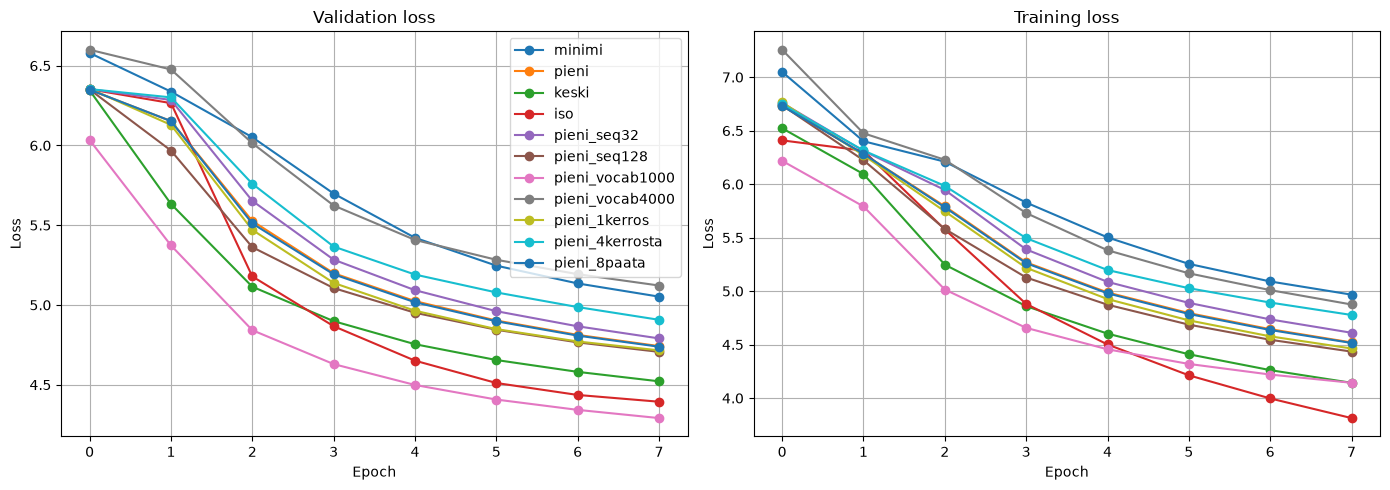

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nimi, t in TULOKSET.items():
    ax[0].plot(t["history"]["val_loss"], marker="o", label=nimi)
    ax[1].plot(t["history"]["loss"], marker="o", label=nimi)
ax[0].set_title("Validation loss")
ax[1].set_title("Training loss")
for a in ax:
    a.set_xlabel("Epoch")
    a.set_ylabel("Loss")
    a.grid()
ax[0].legend()
plt.tight_layout()
plt.show()

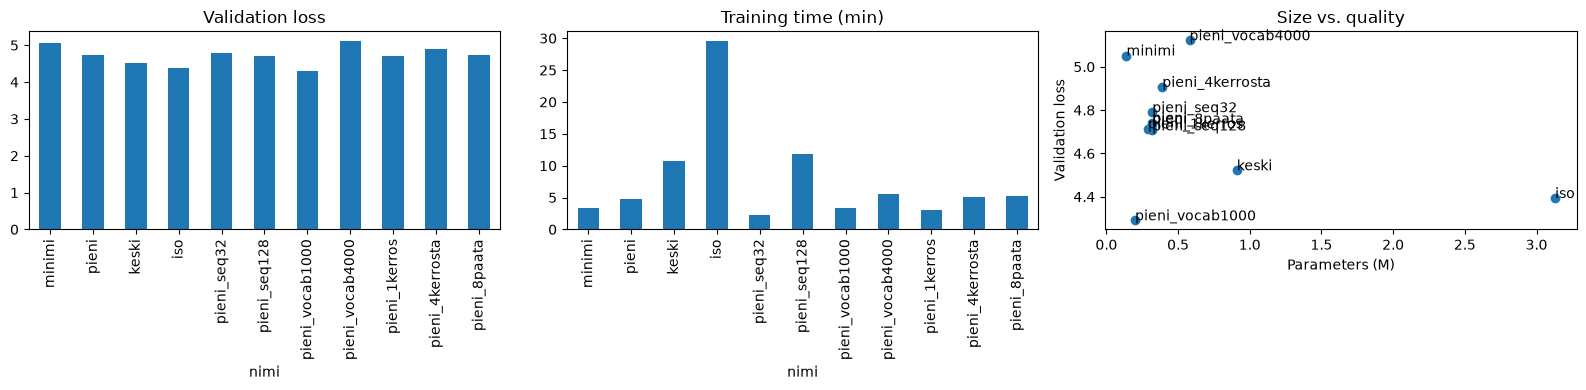

,vocab_size,seq_length,embed_dim,num_heads,ff_dim,num_layers,parametrit_M,epookit,aika_min,val_loss,perplexity,val_acc
nimi,,,,,,,,,,,,
pieni_vocab1000,1000,64,64,2,128,2,0.20,8,3.4,4.291,73.0,0.162
iso,2000,64,256,8,512,4,3.13,8,29.6,4.394,80.9,0.195
keski,2000,64,128,4,256,3,0.91,8,10.8,4.522,92.0,0.179
pieni_seq128,2000,128,64,2,128,2,0.32,8,11.8,4.706,110.6,0.159
pieni_1kerros,2000,64,64,2,128,1,0.29,8,3.1,4.715,111.7,0.157
pieni_8paata,2000,64,64,8,128,2,0.32,8,5.3,4.738,114.3,0.159
pieni,2000,64,64,2,128,2,0.32,8,4.7,4.742,114.7,0.160
pieni_seq32,2000,32,64,2,128,2,0.32,8,2.2,4.790,120.4,0.157
pieni_4kerrosta,2000,64,64,2,128,4,0.39,8,5.1,4.907,135.2,0.147


In [13]:
df = taulukko()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["val_loss"].plot.bar(ax=ax[0], title="Validation loss")
df["aika_min"].plot.bar(ax=ax[1], title="Training time (min)")
ax[2].scatter(df["parametrit_M"], df["val_loss"])
for nimi, r in df.iterrows():
    ax[2].annotate(nimi, (r["parametrit_M"], r["val_loss"]))
ax[2].set_xlabel("Parameters (M)")
ax[2].set_ylabel("Validation loss")
ax[2].set_title("Size vs. quality")
plt.tight_layout()
plt.show()

df.sort_values("val_loss")

## Tekstin generointi

In [14]:
def generate_text(model, sp, prompt, seq_length, num_tokens=60, temperature=1.0):
    """
    Generate text autoregressively.

    Args:
        temperature: Controls randomness
            - Low (0.1-0.5): Focused, repetitive
            - Medium (0.7-1.0): Balanced
            - High (1.5+): Creative, chaotic
    """
    pad_id = sp.piece_to_id("<PAD>")
    input_ids = sp.encode_as_ids(prompt)
    generated_ids = list(input_ids)

    if len(input_ids) < seq_length:
        input_ids = [pad_id] * (seq_length - len(input_ids)) + input_ids
    else:
        input_ids = input_ids[-seq_length:]

    for _ in range(num_tokens):
        x = np.array([input_ids])
        logits = np.array(model(x, training=False)[0, -1], dtype=np.float64)
        logits = logits / max(temperature, 1e-3)
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(int(next_token))
        input_ids = input_ids[1:] + [int(next_token)]

    return sp.decode(generated_ids)

def generoi(nimi, prompt, temperature=1.0, num_tokens=60):
    t = TULOKSET[nimi]
    return generate_text(t["model"], t["sp"], prompt, t["seq_length"], num_tokens, temperature)

In [15]:
# Paras malli = pienin validation loss
PARAS = taulukko()["val_loss"].idxmin()
print("Best model:", PARAS)

PROMPTS = [
    "Sherlock Holmes",
    "\"Watson,\" said Holmes,",
    "It is a capital mistake to theorize",
    "The case was",
]
LAMPOTILAT = [0.2, 0.5, 1.0, 1.5]

np.random.seed(1)
for prompt in PROMPTS:
    print("=" * 100)
    print("PROMPT:", prompt)
    for T in LAMPOTILAT:
        print(f"\n--- temperature {T} ---")
        print(generoi(PARAS, prompt, T))

Best model: pieni_vocab1000
PROMPT: Sherlock Holmes

--- temperature 0.2 ---
Sherlock Holmes, and a lounight of the cably, and a little forested, and the floor of the move of the corner of the grenight, and the madding of the ter of the cir of the corner

--- temperature 0.5 ---
Sherlock Holmes, and he had able in the first which were a corner of the grounds which said he had been a few minutes. “I have seen in the durbende, and withinary, I only not. “It is not five too, for a

--- temperature 1.0 ---
Sherlock Holmes creed of them read from Can in sevate sister had seen his mindside to the ces of the sconeoust. It was in other dak. And on to Mr. “quan your ariain! You are been even near mad

--- temperature 1.5 ---
Sherlock Holmes carhing their mads that comptcolonildfultm the for just hair. Ry every smark arile, lauard. he was dagin, seen a gone in havingown, unffects into your advightureance the case Holmes deep
PROMPT: "Watson," said Holmes,

--- temperature 0.2 ---
 ⁇ Watson, ⁇  s

## Tekstin generointi: mallien vertailu

In [16]:
# Sama aloitusteksti ja lämpötila, eri mallit
np.random.seed(2)
prompt = "\"Watson,\" said Holmes,"
for nimi in ["minimi", "pieni", "keski", "iso"]:
    r = TULOKSET[nimi]["rivi"]
    print(f"--- {nimi} ({r['parametrit_M']} M, val_loss {r['val_loss']}, {r['aika_min']} min) ---")
    print(generoi(nimi, prompt, 0.8, 80))
    print()

--- minimi (0.14 M, val_loss 5.052, 3.4 min) ---
 ⁇ Watson, ⁇  said Holmes, and a found that to being her for the commice and my victaled, to have a us to the doubt that the man,” said I may have been for she would be gru chirizzet at her gluroom and he told ited to thea-conds of the friends tohemne from the vam, but “You must be

--- pieni (0.32 M, val_loss 4.742, 4.7 min) ---
 ⁇ Watson, ⁇  said Holmes, that the company.’ “‘Oh, Doctor will be a charge of the insulting. But I set out out in the inspector has been whped with the great wood “And as it?” “Well, I had a few fact that the preneness upon the air’clock to what I answered.” “I never to be done the mouryed a chat into the very

--- keski (0.91 M, val_loss 4.522, 10.8 min) ---
 ⁇ Watson, ⁇  said Holmes, when he had been left nervome force upon the bentures. Then he held his eyes waited his visitors appearitior across the frree, and finally there is a tission. And yet, far there was the man, but I think that she was quite less an

## Toistuvuus lämpötilan funktiona

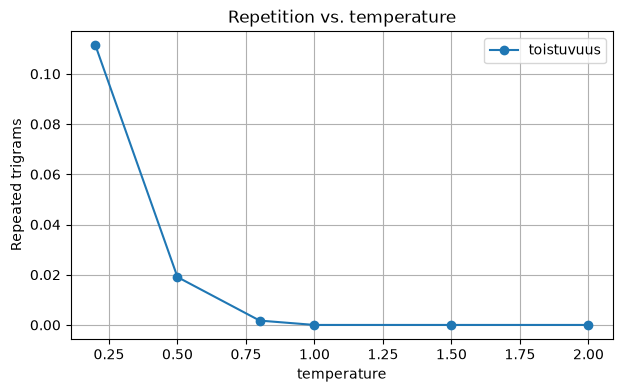

,toistuvuus
temperature,
0.2,0.111509
0.5,0.019063
0.8,0.001736
1.0,0.000000
1.5,0.000000
2.0,0.000000


In [17]:
def toistuvuus(teksti):
    """Share of repeated word trigrams: 0 = no repetition, 1 = fully repetitive."""
    sanat = teksti.lower().split()
    kolmikot = list(zip(sanat, sanat[1:], sanat[2:]))
    return 1 - len(set(kolmikot)) / max(len(kolmikot), 1)

np.random.seed(3)
rivit = []
for T in [0.2, 0.5, 0.8, 1.0, 1.5, 2.0]:
    tekstit = [generoi(PARAS, p, T, 150) for p in PROMPTS for _ in range(3)]
    rivit.append({"temperature": T, "toistuvuus": np.mean([toistuvuus(t) for t in tekstit])})
tul = pd.DataFrame(rivit).set_index("temperature")
tul.plot(marker="o", figsize=(7, 4), title="Repetition vs. temperature")
plt.ylabel("Repeated trigrams")
plt.grid()
plt.show()
tul

## Tallennus

In [18]:
TULOKSET[PARAS]["model"].save("sherlock_model.keras")
taulukko().to_csv("osa1_tulokset.csv")
print("Saved sherlock_model.keras and osa1_tulokset.csv")
taulukko().sort_values("val_loss")

Saved sherlock_model.keras and osa1_tulokset.csv


,vocab_size,seq_length,embed_dim,num_heads,ff_dim,num_layers,parametrit_M,epookit,aika_min,val_loss,perplexity,val_acc
nimi,,,,,,,,,,,,
pieni_vocab1000,1000,64,64,2,128,2,0.20,8,3.4,4.291,73.0,0.162
iso,2000,64,256,8,512,4,3.13,8,29.6,4.394,80.9,0.195
keski,2000,64,128,4,256,3,0.91,8,10.8,4.522,92.0,0.179
pieni_seq128,2000,128,64,2,128,2,0.32,8,11.8,4.706,110.6,0.159
pieni_1kerros,2000,64,64,2,128,1,0.29,8,3.1,4.715,111.7,0.157
pieni_8paata,2000,64,64,8,128,2,0.32,8,5.3,4.738,114.3,0.159
pieni,2000,64,64,2,128,2,0.32,8,4.7,4.742,114.7,0.160
pieni_seq32,2000,32,64,2,128,2,0.32,8,2.2,4.790,120.4,0.157
pieni_4kerrosta,2000,64,64,2,128,4,0.39,8,5.1,4.907,135.2,0.147
